# RAG Results Dashboard

Visualiza las últimas trazas, evaluaciones y riesgos del sistema RAG.

Fuentes:
- `traces` (incluye `client_id`, `cost_estimate_usd`, `risk_level`, tokens)
- `evaluations` (las 8 métricas de gobernanza)
- `response_risks` (risk_level + razones)

Salidas: `summary.csv` y `summary.png` en la carpeta de trabajo.

## 1. Setup

In [1]:
import os
import sys
from datetime import datetime, timedelta, timezone

import pandas as pd
import matplotlib.pyplot as plt

# Resolve repo root so we can import the app modules
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir)) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

from app.db.supabase import get_supabase_client

db = get_supabase_client()
print('Supabase client ready')

2026-04-29 23:36:03,127 | app.db.supabase | INFO | Initializing Supabase client...
2026-04-29 23:36:03,195 | app.db.supabase | INFO | Supabase client initialized for: https://oqahrrauhbleyxaianli.supabase.co
Supabase client ready


## 2. Cargar las últimas 100 trazas

In [2]:
CLIENT_ID = os.environ.get('NB_CLIENT_ID', 'dev-tenant')
DAYS_BACK = int(os.environ.get('NB_DAYS_BACK', '30'))
LIMIT = int(os.environ.get('NB_LIMIT', '100'))

since = (datetime.now(timezone.utc) - timedelta(days=DAYS_BACK)).isoformat()

traces_q = (
    db.table('traces')
    .select('id, user_query, response_text, use_case, model_provider, model_name, latency_ms, cost_estimate_usd, prompt_tokens, completion_tokens, risk_level, requires_disclaimer, client_id, tenant_id, created_at')
    .order('created_at', desc=True)
    .limit(LIMIT)
)
try:
    traces_q = traces_q.eq('client_id', CLIENT_ID).gte('created_at', since)
except Exception:
    pass

traces_df = pd.DataFrame(traces_q.execute().data or [])
print(f'Traces loaded: {len(traces_df)}')
traces_df.head()

Traces loaded: 56


,id,user_query,response_text,use_case,model_provider,model_name,latency_ms,cost_estimate_usd,prompt_tokens,completion_tokens,risk_level,requires_disclaimer,client_id,tenant_id,created_at
0,b1b43240-9dd7-47c7-aa0c-7f2bd6fd3a58,Dame uno de los controles del Anexo A de ISO 4...,Uno de los controles del Anexo A de ISO 42001 ...,chatbot,openai,gpt-4o-mini,4463,0.000948,6019.0,76.0,high,False,dev-tenant,dev-tenant,2026-04-30T04:53:05.082788+00:00
1,d400a5f7-b851-4a71-8474-2a39ddaecfb8,Dime uno de los 38 controles del Anexo A de IS...,No tengo información suficiente en los documen...,chatbot,openai,gpt-4o-mini,9546,0.000948,6005.0,78.0,high,False,dev-tenant,dev-tenant,2026-04-30T04:47:46.411467+00:00
2,e8008e49-c537-4c3a-920d-87958aa890fe,Dime uno de los 38 controles del Anexo A de IS...,No tengo información suficiente en los documen...,chatbot,openai,gpt-4o-mini,4230,0.000874,5436.0,97.0,high,False,dev-tenant,dev-tenant,2026-04-30T04:11:16.543734+00:00
3,fd0a2487-35c3-4af9-8728-7611955d7cbd,Dime uno de los 38 controles de IA segun la IS...,No tengo información suficiente en los documen...,chatbot,openai,gpt-4o-mini,2268,0.000522,3113.0,92.0,high,False,dev-tenant,dev-tenant,2026-04-30T03:52:05.265244+00:00
4,5e39ad27-3f8a-4220-962f-0701580e748a,Dime uno de los 30 controles de IA segun la IS...,No tengo información suficiente en los documen...,chatbot,openai,gpt-4o-mini,2647,0.000523,3113.0,93.0,high,False,dev-tenant,dev-tenant,2026-04-30T03:51:36.346333+00:00


In [3]:
if traces_df.empty:
    raise SystemExit('No hay trazas. Ejecuta algunas consultas a /ai/query primero.')

trace_ids = traces_df['id'].tolist()

evals_df = pd.DataFrame(
    db.table('evaluations')
    .select('trace_id, retrieval_precision, groundedness_score, context_adherence_score, citation_score, completeness_score, instruction_adherence_score, hallucination, should_have_said_idk, claims_total, claims_supported, passed, grounding_score')
    .in_('trace_id', trace_ids)
    .execute().data or []
)
print(f'Evaluations loaded: {len(evals_df)}')

risks_df = pd.DataFrame(
    db.table('response_risks')
    .select('trace_id, risk_level, confidence_score, retrieval_confidence, risk_reasons')
    .in_('trace_id', trace_ids)
    .execute().data or []
)
print(f'Risks loaded: {len(risks_df)}')

df = traces_df.merge(evals_df, left_on='id', right_on='trace_id', how='left', suffixes=('', '_eval'))
df = df.merge(risks_df, left_on='id', right_on='trace_id', how='left', suffixes=('', '_risk'))
if 'risk_level_risk' in df.columns:
    df['risk_level'] = df['risk_level'].fillna(df['risk_level_risk'])
df.head()

Evaluations loaded: 50
Risks loaded: 7


,id,user_query,response_text,use_case,model_provider,model_name,latency_ms,cost_estimate_usd,prompt_tokens,completion_tokens,...,should_have_said_idk,claims_total,claims_supported,passed,grounding_score,trace_id_risk,risk_level_risk,confidence_score,retrieval_confidence,risk_reasons
0,b1b43240-9dd7-47c7-aa0c-7f2bd6fd3a58,Dame uno de los controles del Anexo A de ISO 4...,Uno de los controles del Anexo A de ISO 42001 ...,chatbot,openai,gpt-4o-mini,4463,0.000948,6019.0,76.0,...,False,0.0,0.0,False,0.0419,b1b43240-9dd7-47c7-aa0c-7f2bd6fd3a58,high,0.2938,0.5068,[low_groundedness (0.04 < 0.1)]
1,d400a5f7-b851-4a71-8474-2a39ddaecfb8,Dime uno de los 38 controles del Anexo A de IS...,No tengo información suficiente en los documen...,chatbot,openai,gpt-4o-mini,9546,0.000948,6005.0,78.0,...,False,0.0,0.0,False,0.0133,d400a5f7-b851-4a71-8474-2a39ddaecfb8,high,0.1153,0.5284,"[hallucination_detected, low_context_adherence..."
2,e8008e49-c537-4c3a-920d-87958aa890fe,Dime uno de los 38 controles del Anexo A de IS...,No tengo información suficiente en los documen...,chatbot,openai,gpt-4o-mini,4230,0.000874,5436.0,97.0,...,False,0.0,0.0,False,0.0150,e8008e49-c537-4c3a-920d-87958aa890fe,high,0.1158,0.5174,"[hallucination_detected, low_context_adherence..."
3,fd0a2487-35c3-4af9-8728-7611955d7cbd,Dime uno de los 38 controles de IA segun la IS...,No tengo información suficiente en los documen...,chatbot,openai,gpt-4o-mini,2268,0.000522,3113.0,92.0,...,False,0.0,0.0,False,0.0113,fd0a2487-35c3-4af9-8728-7611955d7cbd,high,0.1116,0.4624,"[hallucination_detected, low_context_adherence..."
4,5e39ad27-3f8a-4220-962f-0701580e748a,Dime uno de los 30 controles de IA segun la IS...,No tengo información suficiente en los documen...,chatbot,openai,gpt-4o-mini,2647,0.000523,3113.0,93.0,...,False,0.0,0.0,False,0.0113,5e39ad27-3f8a-4220-962f-0701580e748a,high,0.1118,0.4673,"[hallucination_detected, low_context_adherence..."


## 3. Distribución de risk_level

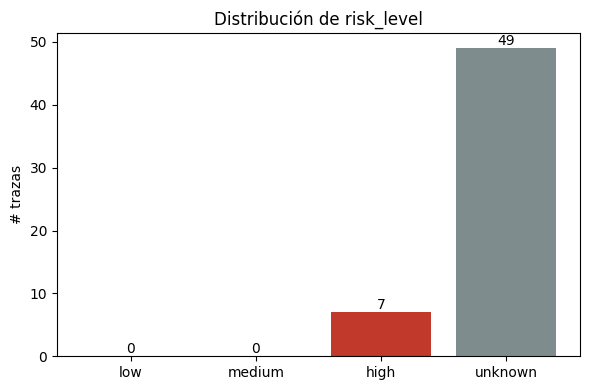

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
risk_counts = (
    df['risk_level'].fillna('unknown').value_counts().reindex(['low', 'medium', 'high', 'unknown']).fillna(0)
)
colors = {'low': '#3aa757', 'medium': '#f1c40f', 'high': '#c0392b', 'unknown': '#7f8c8d'}
ax.bar(risk_counts.index, risk_counts.values, color=[colors[r] for r in risk_counts.index])
ax.set_title('Distribución de risk_level')
ax.set_ylabel('# trazas')
for i, v in enumerate(risk_counts.values):
    ax.text(i, v, str(int(v)), ha='center', va='bottom')
plt.tight_layout(); plt.show()

## 4. Histograma de context_adherence_score

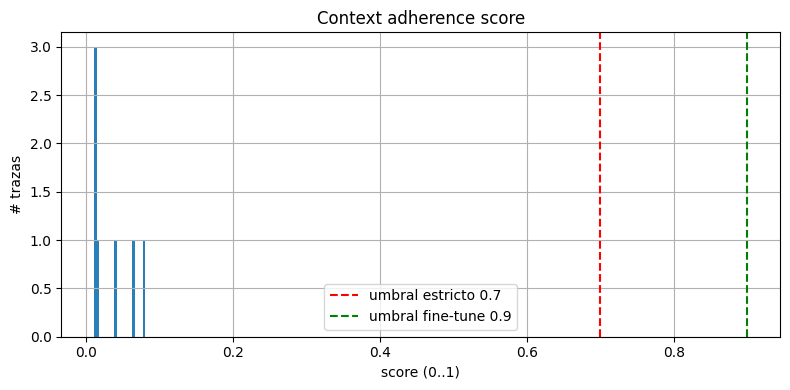

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
df['context_adherence_score'].dropna().astype(float).hist(bins=20, ax=ax, color='#2980b9')
ax.set_title('Context adherence score')
ax.set_xlabel('score (0..1)')
ax.set_ylabel('# trazas')
ax.axvline(0.7, color='red', linestyle='--', label='umbral estricto 0.7')
ax.axvline(0.9, color='green', linestyle='--', label='umbral fine-tune 0.9')
ax.legend()
plt.tight_layout(); plt.show()

## 5. Hallucination rate por use_case

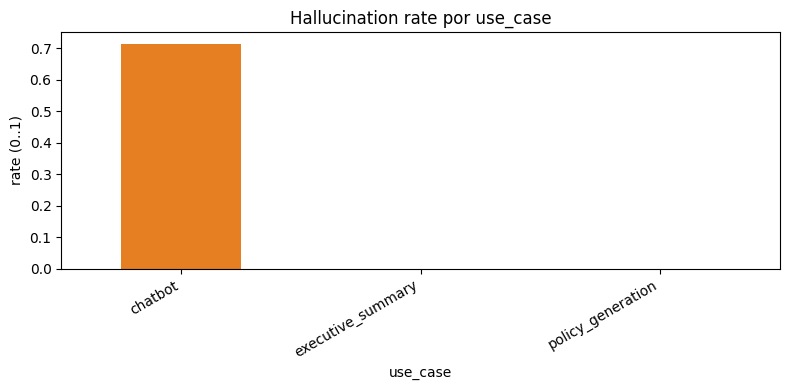

use_case
chatbot              0.714286
executive_summary         NaN
policy_generation         NaN
Name: hallucination, dtype: object


In [6]:
if 'hallucination' in df.columns and df['hallucination'].notna().any():
    rate = df.groupby('use_case')['hallucination'].mean().sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(8, 4))
    rate.plot.bar(ax=ax, color='#e67e22')
    ax.set_title('Hallucination rate por use_case')
    ax.set_ylabel('rate (0..1)')
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout(); plt.show()
    print(rate)
else:
    print('No hay columna hallucination todavía. Aplica la migración 006 y vuelve a ejecutar /ai/query.')

## 6. Latencia y costo por modelo

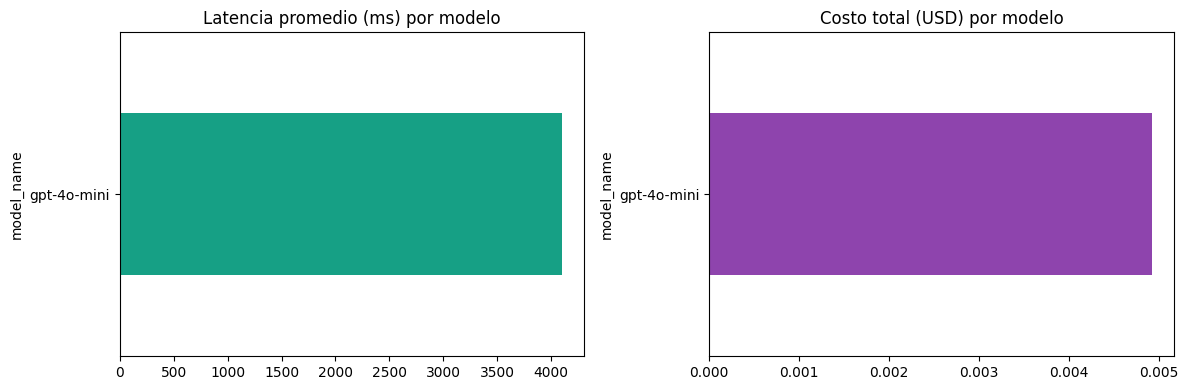

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df.groupby('model_name')['latency_ms'].mean().sort_values().plot.barh(ax=axes[0], color='#16a085')
axes[0].set_title('Latencia promedio (ms) por modelo')
if 'cost_estimate_usd' in df.columns:
    df.groupby('model_name')['cost_estimate_usd'].sum().sort_values().plot.barh(ax=axes[1], color='#8e44ad')
    axes[1].set_title('Costo total (USD) por modelo')
plt.tight_layout(); plt.show()

## 7. Top 10 documentos más recuperados

In [8]:
trace_ids_for_chunks = traces_df['id'].tolist()
rows = (
    db.table('traces')
    .select('id, retrieved_chunk_ids')
    .in_('id', trace_ids_for_chunks)
    .execute().data or []
)

all_chunk_ids = []
for r in rows:
    cids = r.get('retrieved_chunk_ids') or []
    all_chunk_ids.extend(cids)

if all_chunk_ids:
    chunk_to_doc = {
        c['id']: c['document_id']
        for c in db.table('document_chunks').select('id, document_id').in_('id', list(set(all_chunk_ids))).execute().data or []
    }
    docs = pd.DataFrame(
        db.table('documents').select('id, filename, framework').in_('id', list(set(chunk_to_doc.values()))).execute().data or []
    ).set_index('id')
    doc_counts = pd.Series([
        docs.loc[chunk_to_doc[c]].filename if chunk_to_doc.get(c) in docs.index else 'unknown'
        for c in all_chunk_ids
    ]).value_counts().head(10)
    fig, ax = plt.subplots(figsize=(8, 5))
    doc_counts.iloc[::-1].plot.barh(ax=ax, color='#34495e')
    ax.set_title('Top 10 documentos más recuperados')
    plt.tight_layout(); plt.show()
else:
    print('No hay chunks recuperados en el rango.')

APIError: {'message': 'invalid input syntax for type uuid: "7"', 'code': '22P02', 'hint': None, 'details': None}

## 8. Ejemplos HIGH risk con razones

In [ ]:
high = df[df['risk_level'] == 'high'][['id', 'use_case', 'user_query', 'risk_reasons', 'context_adherence_score', 'hallucination']].head(10)
if high.empty:
    print('Ninguna respuesta HIGH risk en la ventana 🎉')
else:
    for _, row in high.iterrows():
        print('-' * 60)
        print(f"trace_id: {row['id']}")
        print(f"use_case: {row['use_case']}")
        print(f"query:    {row['user_query'][:140]}")
        print(f"reasons:  {row['risk_reasons']}")
        print(f"adherence: {row['context_adherence_score']}, hallucination: {row['hallucination']}")

## 9. Exportar `summary.csv` y `summary.png`

In [ ]:
summary = pd.DataFrame({
    'metric': [
        'total_calls', 'avg_latency_ms', 'total_cost_usd', 'avg_context_adherence',
        'hallucination_rate', 'high_risk_count', 'medium_risk_count', 'low_risk_count'
    ],
    'value': [
        len(df),
        round(df['latency_ms'].mean(), 2) if 'latency_ms' in df.columns else None,
        round(df['cost_estimate_usd'].sum(), 6) if 'cost_estimate_usd' in df.columns else None,
        round(df['context_adherence_score'].mean(), 4) if 'context_adherence_score' in df.columns else None,
        round(df['hallucination'].mean(), 4) if 'hallucination' in df.columns else None,
        int((df['risk_level'] == 'high').sum()),
        int((df['risk_level'] == 'medium').sum()),
        int((df['risk_level'] == 'low').sum()),
    ]
})
summary.to_csv('summary.csv', index=False)
print('Wrote summary.csv')

fig, ax = plt.subplots(figsize=(7, 5))
(df['risk_level'].fillna('unknown').value_counts().reindex(['low', 'medium', 'high', 'unknown']).fillna(0)
 ).plot.bar(ax=ax, color=['#3aa757', '#f1c40f', '#c0392b', '#7f8c8d'])
ax.set_title('Risk distribution (window)')
ax.set_ylabel('# trazas')
plt.tight_layout(); plt.savefig('summary.png', dpi=150)
print('Wrote summary.png')